# Aim of the notebook

Visualize the main uRNA quantification (Figure 1 and 2)

# Import modules

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
import os

parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../../src/troutpy_reproducibility"))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from batch_running import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
import os
import pandas as pd

# Define the root directory
root_dir = "/media/sergio/Meninges/troutpy/rois"
saving_path='/media/sergio/Meninges/troutpy/figures'

# Initialize an empty list to hold individual metadata DataFrames
metadata_list = []

# List only first-level subdirectories
subfolders = [f.path for f in os.scandir(root_dir) if f.is_dir()]

for subfolder in subfolders:
    #    sub=os.path.join(root_dir,subfolder)
    metadata_path = os.path.join(subfolder, "figures/pipeline_summary.csv")
    print(metadata_path)
    if os.path.isfile(metadata_path):
        try:
            df = pd.read_csv(metadata_path)
            df.index = [subfolder.split("/")[-1]]
            # Add subfolder name as a column
            metadata_list.append(df)
        except Exception as e:
            print(f"Failed to read {metadata_path}: {e}")
# Combine all metadata files into a single DataFrame
if metadata_list:
    combined_summary = pd.concat(metadata_list, ignore_index=False)
    print("Combined metadata shape:", combined_summary.shape)
else:
    print("No metadata.csv files found.")

combined_summary["proportion_of_cell_like"] = (1 - combined_summary["proportion_of_segmented"] - combined_summary["proportion_of_extracellular"])

/media/sergio/Meninges/troutpy/rois/cosmx_hgsoc/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/cosmx_melanoma/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/cosmx_mousebrain/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/cosmx_pancreas/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/cosmx_stomach/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/merscope_hsbrain/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/merscope_hsuterine/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/xenium_hsfemur/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/xenium_hsheart/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/xenium_hsprostate/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/xenium_hsputamen/figures/pipeline_summary.csv
/media/sergio/Meninges/troutpy/rois/xenium_hsskin_5k/figures/pipeline_summary.csv
/media/sergio/Meninges/troutp

In [13]:
np.max(combined_summary['proportion_of_cell_like'])

0.8419296861551415

## Plots to define cell characteristics

In [43]:
combined_summary["proportion_of_cell_like"] = (1 - combined_summary["proportion_of_segmented"] - combined_summary["proportion_of_extracellular"])

import matplotlib.pyplot as plt

proportions = combined_summary.loc[:, ["proportion_of_extracellular", "proportion_of_cell_like", "proportion_of_segmented"]]
proportions = proportions.sort_values(by="proportion_of_extracellular")

In [44]:
proportions['proportion_of_extracellular_noise']=proportions['proportion_of_extracellular']*combined_summary['noise_RNA_proportion']
proportions['proportion_of_extracellular_non_noise']=proportions['proportion_of_extracellular']*(1-combined_summary['noise_RNA_proportion'])
proportions['proportion_of_extracellular_diffussion']=proportions['proportion_of_extracellular_non_noise']*combined_summary['diffussion_RNA_proportion']
proportions['proportion_of_extracellular_other']=proportions['proportion_of_extracellular_non_noise']*(1-combined_summary['diffussion_RNA_proportion'])

In [45]:
combined_proportion=proportions.loc[:,['proportion_of_segmented','proportion_of_cell_like','proportion_of_extracellular_noise','proportion_of_extracellular_diffussion','proportion_of_extracellular_other']]

In [46]:
combined_proportion=combined_proportion.sort_index()

In [47]:
dataset_order=['cosmx_hgsoc', 'cosmx_melanoma', 'cosmx_mousebrain', 'cosmx_stomach',
       'merscope_hsbrain', 'merscope_hsuterine',
        'xenium_hsprostate', 'xenium_hsskin_5k',
       'xenium_mscolon_5k', 'xenium_msbrain_5k','xenium_msbrain_300','xenium_hsputamen','xenium_hsheart','xenium_hsfemur']
combined_proportion=combined_proportion.loc[dataset_order,:]

In [41]:
np.mean(combined_summary['diffussion_RNA_proportion'])

0.24912993801667588

<Figure size 400x100 with 0 Axes>

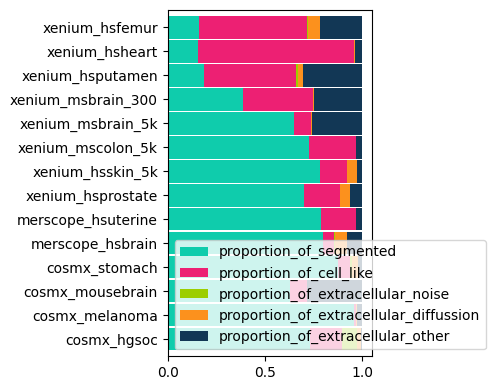

In [23]:


# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Define your custom list of colors (hex or named)
custom_colors = ["#0FCCAC",
            "#ED2073",
             "#9CCE00",
            "#FC911D",
            "#123755",
            "#790DB7",

            "#010101",
            "#F7C894",
            "#BCBCBC",]  # Example list

# Plot
plt.figure(figsize=(4,1))  # This is not necessary if using figsize in plot()
combined_proportion.plot(
    kind='barh',
    stacked=True,
    width=0.95,
    figsize=(4,4),
    color=custom_colors
)

# Save figure
plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'stacked_barplot.pdf'))


In [31]:
#combined_proportion['cell_like_urna_proportion']=combined_proportion['proportion_of_cell_like']/(1-combined_proportion['proportion_of_segmented'])

In [49]:
combined_proportion.pop('proportion_of_segmented')

cosmx_hgsoc           0.732539
cosmx_melanoma        0.957968
cosmx_mousebrain      0.626943
cosmx_stomach         0.874164
merscope_hsbrain      0.796430
merscope_hsuterine    0.786092
xenium_hsprostate     0.700679
xenium_hsskin_5k      0.782788
xenium_mscolon_5k     0.726493
xenium_msbrain_5k     0.649773
xenium_msbrain_300    0.387105
xenium_hsputamen      0.185727
xenium_hsheart        0.158070
xenium_hsfemur        0.160644
Name: proportion_of_segmented, dtype: float64

In [53]:
combined_proportion_norm=combined_proportion.div(combined_proportion.sum(axis=1),axis=0)

In [55]:
np.mean(combined_proportion_norm,axis=0)

proportion_of_cell_like                   0.567721
proportion_of_extracellular_noise         0.031466
proportion_of_extracellular_diffussion    0.089711
proportion_of_extracellular_other         0.311102
dtype: float64

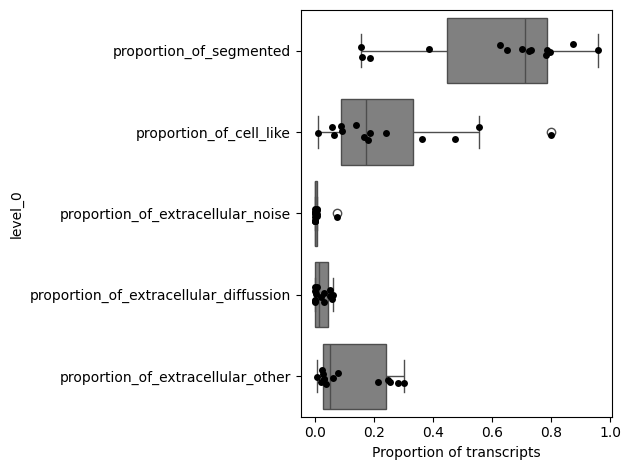

In [18]:
combined_unstack=combined_proportion.unstack().reset_index()
sns.boxplot(data=combined_unstack,y='level_0',x=0,color='grey')
sns.stripplot(data=combined_unstack,y='level_0',x=0,color='black',s=5)
plt.tight_layout()
plt.xlabel('Proportion of transcripts')
plt.savefig(os.path.join(saving_path, 'boxplot_per_sample_trascript_type_proportion.pdf'))

In [16]:
proportions['proportion_of_extracellular']

xenium_hsheart        0.015940
xenium_mscolon_5k     0.031052
cosmx_melanoma        0.031102
cosmx_stomach         0.060767
xenium_hsskin_5k      0.078457
cosmx_hgsoc           0.102217
xenium_hsfemur        0.108754
xenium_hsprostate     0.113422
merscope_hsbrain      0.145630
xenium_msbrain_300    0.251141
Name: proportion_of_extracellular, dtype: float64

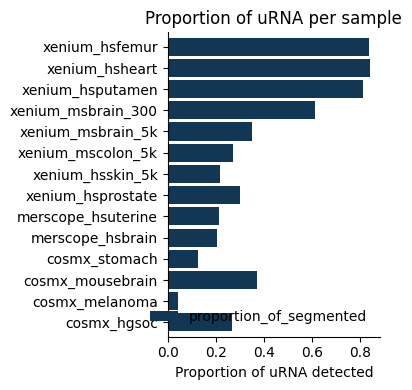

In [23]:
import matplotlib.pyplot as plt

proportions = combined_summary.loc[:, ["proportion_of_segmented"]]
proportions=proportions.loc[dataset_order,:]
proportions=1-proportions
ax = proportions.plot(
    kind="barh",
    stacked=True,
    width=0.85,
    color="#123755",
    figsize=(4, 4)
)

# Remove the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend at bottom right, without box
ax.legend(
    loc='lower right',
    frameon=False
)

plt.xlabel("Proportion of uRNA detected")
plt.ylabel("")
plt.title("Proportion of uRNA per sample")
plt.tight_layout()

plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'stacked_barplot_proportions_segmented.pdf'))
plt.show()


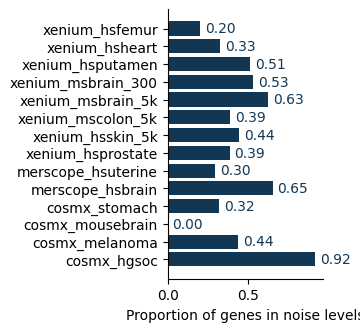

In [47]:
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
combined_summary=combined_summary.loc[dataset_order,:]

plt.figure(figsize=(2, 3.5))
bars = plt.barh(
    combined_summary.index,
    1-combined_summary["genes_prop_over_noise"],
    color=troutpy.pl.get_palette("30colors")[2:3]
)

# Add text labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.03,               # x-position
        bar.get_y() + bar.get_height() / 2,  # y-position (center of bar)
        f"{width:.2f}",             # formatted number
        va='center',
        ha='left',
        color='#123755',
        fontsize=10
    )

# Remove the top and right spines (square look)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel("Proportion of genes in noise levels")

plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'barplot_proportions_of_noise_genes.pdf'))

plt.show()


In [40]:
np.mean(1-combined_summary["proportion_non_diffussion"])

0.3154763481122907

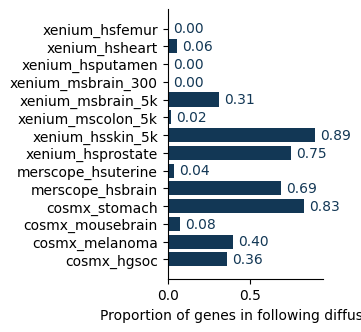

In [48]:
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
combined_summary=combined_summary.loc[dataset_order,:]

plt.figure(figsize=(2, 3.5))
bars = plt.barh(
    combined_summary.index,
    1-combined_summary["proportion_non_diffussion"],
    color=troutpy.pl.get_palette("30colors")[2:3]
)

# Add text labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.03,               # x-position
        bar.get_y() + bar.get_height() / 2,  # y-position (center of bar)
        f"{width:.2f}",             # formatted number
        va='center',
        ha='left',
        color='#123755',
        fontsize=10
    )

# Remove the top and right spines (square look)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel("Proportion of genes in following diffussion")

plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'barplot_proportions_of_diffussion.pdf'))

plt.show()


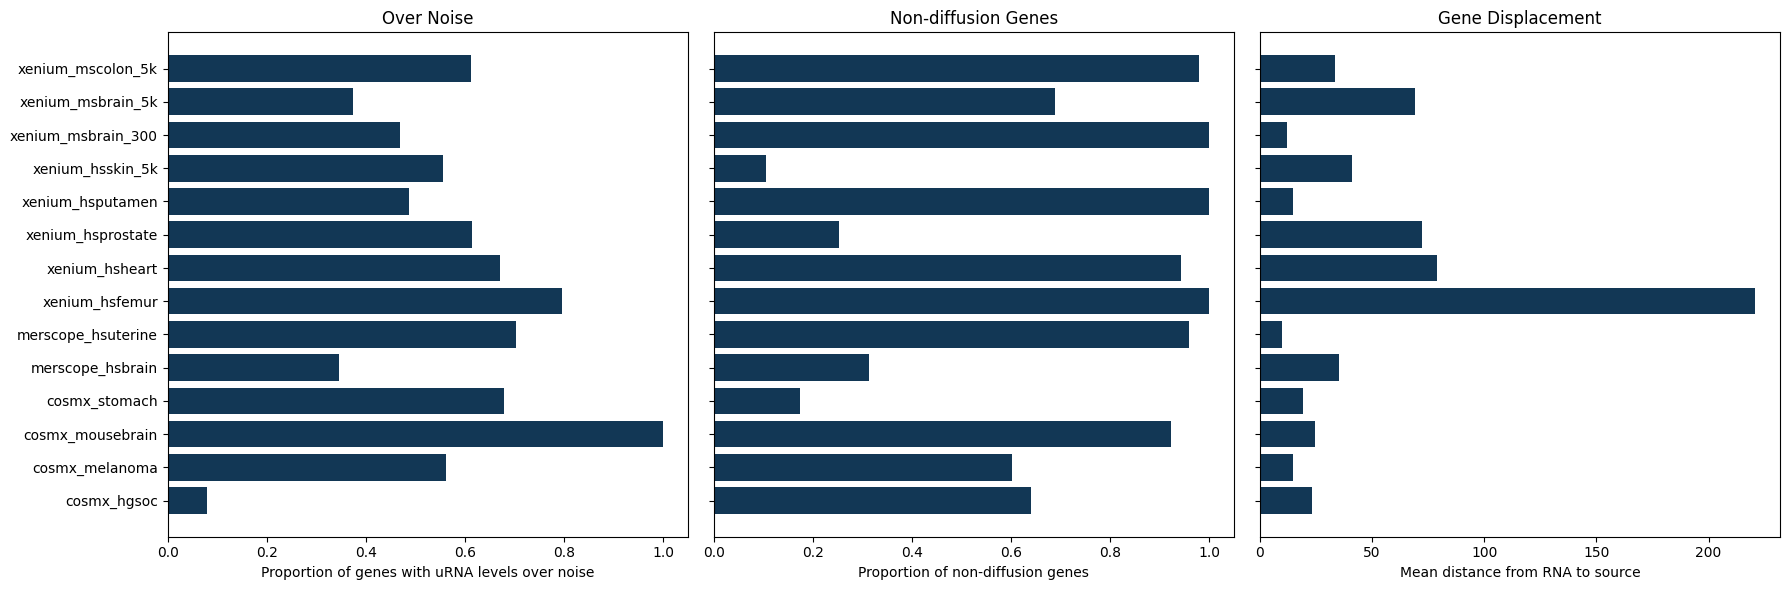

In [41]:
import matplotlib.pyplot as plt

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6), sharey=True)

# First subplot
axes[0].barh(combined_summary.index, combined_summary["genes_prop_over_noise"],color=troutpy.pl.get_palette("30colors")[2:3])
axes[0].set_xlabel("Proportion of genes with uRNA levels over noise")
axes[0].set_title("Over Noise")

# Second subplot
axes[1].barh(combined_summary.index, combined_summary["proportion_non_diffussion"],color=troutpy.pl.get_palette("30colors")[2:3])
axes[1].set_xlabel("Proportion of non-diffusion genes")
axes[1].set_title("Non-diffusion Genes")

# Third subplot
axes[2].barh(combined_summary.index, combined_summary["mean_gene_displacement"],color=troutpy.pl.get_palette("30colors")[2:3])
axes[2].set_xlabel("Mean distance from RNA to source")
axes[2].set_title("Gene Displacement")

plt.tight_layout()
plt.show()